# Multi-Source Building Inventories Demo

This notebook walks through multi-source inventories
([ADR-multi-source](../docs/decisions/ADR-multi-source.md), RQM-04): building
inventories from different sources are loaded **side by side** into the same
`rqm.inventory.buildings` table, each scoped by its `source_ref`, using the NSI
field set as the shared column schema.

1. **Synthetic sources.** Generate three non-NSI inventories from the NSI sample
   and look at the raw data. They have different schemas, CRSs, units, codes,
   and ids.
2. **Source specs.** One YAML mapping spec per source, validated before Spark
   runs, including a spec that is rejected.
3. **Load.** The county assessor → `assessor-r1` and the field survey →
   `survey-2025`, beside the NSI inventory that `02_versioning_demo.ipynb` left
   at `nsi-sample-v7`. Then look at the `sources` registry and the version
   lineage.
4. **One schema across sources.** Occupancy mix, exposed value, footprints vs.
   points, a map, and a note on double counting.
5. **Scoped reload.** Assessor release 2 → `assessor-r2` touches only assessor
   rows.
6. **Project inventory on a branch.** Load a planned development onto a
   `riverbend` branch and merge it into `main`.
7. **Source-filtered pinned export.** Export NSI + assessor with a manifest.
8. **Consistency check** across every version.

**How it works.**
- **Mapping.** Each source is described by a YAML spec (`tools/sources.py`): how
  to read the file (parquet, GeoParquet, CSV, or GeoPackage; CRS; point or
  polygon geometry), which column holds the native id, and how each `buildings`
  column is filled. A column is filled by a rename, a Spark SQL expression
  (e.g. a unit conversion), or a code crosswalk, each with an optional
  default. Unmapped columns are NULL.
- **Identity.** NSI rows keep `building_id = fd_id`. Every other source gets
  `xxhash64(source_ref, source_record_id)` with the sign bit set. Those ids are
  always negative, so they never collide with NSI's, and they stay stable
  across reloads.
- **Scoped loads.** A load is a `MERGE` that fully replaces *its own* source's
  rows; other sources are never touched.
- **Geometry.** Polygon sources get a display footprint plus a computation
  point from `ST_PointOnSurface`. Every geometry is transformed to EPSG:3857.

The data is all synthetic, derived deterministically from
`test/data/nsi.parquet` (`tools/synthetic_sources.py`).

**Run order.** The three demos share one warehouse and catalog
(`test/warehouse-notebook/`). Run `01_setup_demo.ipynb` and
`02_versioning_demo.ipynb` first: this notebook starts from `main` at
`nsi-sample-v7`, the version 02 ends on. To run it again, start over from 01.

## 0. Setup

In [1]:
import json
import shutil
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import shapely
import yaml

# Locate the repo root by walking up from the notebook's cwd.
REPO = Path.cwd().resolve()
while REPO != REPO.parent and not (REPO / "tools" / "ingest_source.py").exists():
    REPO = REPO.parent
assert (REPO / "tools" / "ingest_source.py").exists(), (
    f"repo root not found from {Path.cwd()}"
)
sys.path.insert(0, str(REPO / "tools"))

SAMPLE = REPO / "test" / "data" / "nsi.parquet"
SPECS = REPO / "notebooks" / "sources"
DATA_DIR = Path("/workspaces/rqm-data-model/test")
# The warehouse is shared by the three demos and created by 01_setup_demo.
WAREHOUSE = DATA_DIR / "warehouse-notebook"
assert WAREHOUSE.exists(), f"{WAREHOUSE} not found: run 01_setup_demo.ipynb first"
# The version 02_versioning_demo leaves main at; this notebook builds on it.
BASE_VERSION = "nsi-sample-v7"
# This notebook's own inputs and exports, recreated on every run.
SCRATCH = DATA_DIR / "multi-source-notebook"
INPUTS = SCRATCH / "inputs"
EXPORTS = SCRATCH / "exports"
if SCRATCH.exists():
    shutil.rmtree(SCRATCH)
for d in (INPUTS, EXPORTS):
    d.mkdir(parents=True)

CATALOG = "rqm"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
print(f"sample:    {SAMPLE}")
print(f"warehouse: {WAREHOUSE}")

sample:    /workspaces/rqm-data-model/test/data/nsi.parquet
warehouse: /workspaces/rqm-data-model/test/warehouse-notebook


### Boot Spark + Sedona + Iceberg

Same session and the same shared warehouse as the other demos: a JDBC
(SQLite) Iceberg catalog in `catalog.db`, with the tables in the `inventory`
namespace. `apply_schema` is idempotent; the tables, including the `sources`
registry, already exist. The last lines check that `main` is exactly at
`nsi-sample-v7`, where `02_versioning_demo.ipynb` leaves it.

In [2]:
import ingest_source as src
import versioning as v
from ingest_nsi import (
    NAMESPACE,
    SparkSettings,
    apply_schema,
    build_spark,
    local_master,
    sedona_geom_sql,
    table_name,
)
from sources import SpecError, load_spec, parse_spec
from synthetic_sources import generate_all
from versioning import file_sha256

DRIVER_MEMORY = "8g"
settings = SparkSettings(
    warehouse=WAREHOUSE,
    catalog=CATALOG,
    master=local_master(DRIVER_MEMORY),
    conf={
        "spark.driver.memory": DRIVER_MEMORY,
        "spark.sql.shuffle.partitions": "8",
        "spark.ui.showConsoleProgress": "false",
    },
)
spark = build_spark(settings)
spark.sparkContext.setLogLevel("ERROR")

BUILDINGS = table_name(CATALOG, "buildings")  # rqm.inventory.buildings
GEOMETRIES = table_name(CATALOG, "geometries")  # rqm.inventory.geometries
SOURCES = table_name(CATALOG, "sources")  # rqm.inventory.sources

apply_schema(spark, CATALOG)

# Prerequisite: 02_versioning_demo left main at BASE_VERSION, and nothing has
# been committed on top of it yet.
assert v.find_version(spark, CATALOG, BASE_VERSION) is not None, (
    f"{BASE_VERSION} not found: run 01_setup_demo.ipynb, then 02_versioning_demo.ipynb"
)
head = v.version_at(spark, CATALOG, v.head_snapshots(spark, CATALOG))
assert head == BASE_VERSION, (
    f"main is at {head!r}, not {BASE_VERSION}: rerun 01_setup_demo.ipynb and "
    "02_versioning_demo.ipynb, then this notebook"
)
spark.sql(f"SHOW TABLES IN {CATALOG}.{NAMESPACE}").toPandas()

SLF4J: Failed to load class "org.slf4j.impl.StaticLoggerBinder".
SLF4J: Defaulting to no-operation (NOP) logger implementation
SLF4J: See http://www.slf4j.org/codes.html#StaticLoggerBinder for further details.


:: loading settings :: url = jar:file:/opt/conda/envs/rqm-base/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/vscode/.ivy2.5.2/cache
The jars for the packages stored in: /home/vscode/.ivy2.5.2/jars
org.apache.sedona#sedona-spark-shaded-4.1_2.13 added as a dependency
org.datasyslab#geotools-wrapper added as a dependency
org.apache.iceberg#iceberg-spark-runtime-4.1_2.13 added as a dependency
org.xerial#sqlite-jdbc added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-728a6498-cf3e-4c1b-9345-1f25b325547f;1.0
	confs: [default]
	found org.apache.sedona#sedona-spark-shaded-4.1_2.13;1.9.1 in central
	found org.datasyslab#geotools-wrapper;1.9.1-33.5 in central
	found org.apache.iceberg#iceberg-spark-runtime-4.1_2.13;1.12.0 in central


	found org.xerial#sqlite-jdbc;3.50.3.0 in central
:: resolution report :: resolve 153ms :: artifacts dl 9ms
	:: modules in use:
	org.apache.iceberg#iceberg-spark-runtime-4.1_2.13;1.12.0 from central in [default]
	org.apache.sedona#sedona-spark-shaded-4.1_2.13;1.9.1 from central in [default]
	org.datasyslab#geotools-wrapper;1.9.1-33.5 from central in [default]
	org.xerial#sqlite-jdbc;3.50.3.0 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   4   |   0   |   0   |   0   ||   4   |   0   |
	---------------------------------------------------------------------
:: retrieving :: org.apache.spark#spark-submit-parent-728a6498-cf3e-4c1b-9345-1f25b325547f
	confs: [default]
	0 artifacts copied, 4 already retrieved (0k

SLF4J: Failed to load class "org.slf4j.impl.StaticMDCBinder".
SLF4J: Defaulting to no-operation MDCAdapter implementation.
SLF4J: See http://www.slf4j.org/codes.html#no_static_mdc_binder for further details.


,namespace,tableName,isTemporary
0,inventory,buildings,False
1,inventory,geometries,False
2,inventory,inventory_changes,False
3,inventory,inventory_versions,False
4,inventory,sources,False


In [3]:
def sql(query):
    return spark.sql(query).toPandas()


def commit(version, *, source_ref=None, path=None, branch="main", **kw):
    kw.setdefault("editor", "analyst-a")
    return v.commit_version(
        spark,
        CATALOG,
        version,
        branch=branch,
        source_ref=source_ref,
        source_uri=None if path is None else str(path),
        source_sha256=None if path is None else file_sha256(path),
        **kw,
    )


def load(spec, path, version, *, branch="main", **kw):
    # Validate, register the source, MERGE its buildings + geometries, commit.
    result = src.load_source(spark, spec, path, CATALOG, branch=branch)
    info = commit(version, source_ref=spec.source_ref, path=path, branch=branch, **kw)
    return result, info


def registry():
    cols = [
        "version_name",
        "parent_version",
        "merged_version",
        "branch",
        "kind",
        "source_ref",
        "editor",
        "reason",
        "n_buildings",
        "n_added",
        "n_removed",
        "n_changed",
    ]
    df = v.list_versions(spark, CATALOG).select(*cols).toPandas()
    return df.fillna({"parent_version": "—", "merged_version": "—", "source_ref": "—"})


def per_source(table=BUILDINGS):
    return sql(
        f"SELECT source_ref, COUNT(*) AS n FROM {table} GROUP BY source_ref "
        "ORDER BY source_ref"
    ).set_index("source_ref")["n"]

## 1. Synthetic sources

`generate_all` derives three inventories from the NSI sample. They are
deterministic for a given seed:

| source_ref | Kind | Format | Notes |
|---|---|---|---|
| `COUNTY-ASSESSOR` | local inventory | GeoPackage polygons, EPSG:2276 (TX North Central, US ft) | Dallas County parcels, plus a second release |
| `FIELD-SURVEY-2025` | field survey | CSV with lon / lat (EPSG:4326) | First-floor heights at 300 structures |
| `PROJECT-RIVERBEND` | project inventory | parquet with WKB points (EPSG:3857) | A planned subdivision |

In [4]:
syn = generate_all(SAMPLE, INPUTS)
sorted(p.name for p in INPUTS.iterdir())

['county-assessor-r1.gpkg',
 'county-assessor-r2.gpkg',
 'field-survey-2025.csv',
 'project-riverbend.parquet',
 'truth.json']

**The assessor roll** has its own column names, land-use codes (`A1`, `F1`,
...), first-floor elevation in **inches**, text foundation types, `PARCEL_ID`
ids, and parcel footprints in Texas state-plane feet.

In [5]:
assessor_raw = gpd.read_file(syn.assessor.release1)
print(assessor_raw.crs, len(assessor_raw), "parcels")
assessor_raw.head()

EPSG:2276 548 parcels


,PARCEL_ID,LANDUSE,IMPR_VAL,LAND_VAL,FFE_IN,FOUND,STORIES,YR_BUILT,LIVING_SQFT,BLOCK_GEOID,geometry
0,R0100249,A1,376103,107767,9,SLAB,1.0,2000,1836.0,481130181442043,"POLYGON ((2576482.172 7026534.259, 2576479.29 ..."
1,R0100139,XC,1325840,39156,3,SLAB,1.0,2000,6420.0,481130181442043,"POLYGON ((2576392.598 7024984.534, 2576371.889..."
2,R0100094,A1,468112,141462,9,SLAB,1.0,2000,2516.0,481130181442043,"POLYGON ((2576541.278 7026006.635, 2576525.74 ..."
3,R0100340,A1,462550,187816,9,SLAB,1.0,2000,2506.0,481130181442043,"POLYGON ((2576533.927 7026321.107, 2576533.175..."
4,R0100194,XS,819432,217154,3,SLAB,1.0,2000,3529.0,481130181442043,"POLYGON ((2576551.188 7025709.027, 2576546.592..."


**The field survey** is a CSV with GPS coordinates and only a few attributes.

In [6]:
survey_raw = pd.read_csv(syn.survey)
print(len(survey_raw), "surveyed structures")
survey_raw.head()

300 surveyed structures


,SURVEY_ID,LON,LAT,FFH_FT,FOUNDATION,STORIES,USE_OBSERVED,BLOCK_GEOID,SURVEY_DATE
0,FS25-0001,-96.308661,32.955742,0.5,Slab on grade,2,Residential,483970404112003,2025-06-01
1,FS25-0002,-96.309965,32.956499,1.0,Slab on grade,1,Residential,483970404112006,2025-07-02
2,FS25-0003,-96.314197,32.956320,0.3,Slab on grade,2,Residential,483970404112003,2025-08-03
3,FS25-0004,-96.311518,32.953766,0.4,Slab on grade,2,Residential,483970404112003,2025-09-04
4,FS25-0005,-96.322429,32.959221,0.6,Slab on grade,1,Residential,483970404112007,2025-06-05


**The project inventory** lists planned lots as WKB points in Web Mercator.

In [7]:
riverbend_raw = pd.read_parquet(syn.riverbend)
riverbend_raw.assign(
    geometry=shapely.from_wkb(riverbend_raw["geometry"]).astype(str)
).head()

,LOT_NO,USE,PLANNED_VALUE,FIN_FLOOR_FT,STORIES,FOUND,BLOCK_GEOID,geometry
0,RB-001,RETAIL,1.350793e+06,1.0,1,S,483970404121000,POINT (-10719278.43590364 3885213.095034316)
1,RB-002,RETAIL,1.141920e+06,1.0,1,S,483970404121000,POINT (-10719238.43590364 3885213.095034316)
2,RB-003,SFR,3.983003e+05,2.0,2,S,483970404121000,POINT (-10719198.43590364 3885213.095034316)
3,RB-004,SFR,3.828859e+05,2.0,2,S,483970404121000,POINT (-10719158.43590364 3885213.095034316)
4,RB-005,SFR,3.986619e+05,2.0,2,S,483970404121000,POINT (-10719118.43590364 3885213.095034316)


## 2. Source specs

One YAML spec per source maps it onto the `buildings` columns. Here is the
assessor's. `occtype` and `found_type` are **code crosswalks**, `found_ht`
converts inches to feet with a Spark SQL **expression**, and the plain names
are **renames**.

In [8]:
print((SPECS / "county-assessor.yaml").read_text())

# Demo source spec: a county assessor roll (synthetic; tools/synthetic_sources.py).
# GeoPackage parcel footprints in Texas North Central state plane (US feet),
# with its own column names, land-use codes, units, and parcel ids.
source_ref: COUNTY-ASSESSOR
source_name: Example County Assessor Parcels
source_kind: local_inventory
description: >
  Synthetic county appraisal-district roll: one parcel per improved
  structure with land-use code, improvement value, first-floor elevation
  above grade in inches, and foundation type. Footprints become display
  geometries; the computation point is their point on surface.
input:
  format: gpkg
  layer: parcels
  crs: EPSG:2276
  geometry: {kind: polygon, column: geom}
id: {column: PARCEL_ID}
fields:
  # Land-use code -> occupancy crosswalk (lossy); unknown codes get RES1.
  occtype:
    from: LANDUSE
    map: {A1: RES1, A2: RES2, B1: RES3C, B2: RES3A, F1: COM1, F2: IND2, D2: AGR1, XG: GOV1, XC: REL1, XS: EDU1}
    default: RES1
  st_damcat:
  

`load_spec` validates a spec in pure Python before Spark touches any data. It
checks that the targets are known `buildings` columns, that crosswalk values
are valid enum codes, that `occtype` is mapped or defaulted, and that the CRS
and geometry kind are well formed. The built-in NSI spec
(`tools/sources/nsi.yaml`) is an identity mapping.

In [9]:
from sources import nsi_spec

specs = {
    "nsi": nsi_spec(),
    "assessor": load_spec(SPECS / "county-assessor.yaml"),
    "survey": load_spec(SPECS / "field-survey-2025.yaml"),
    "riverbend": load_spec(SPECS / "project-riverbend.yaml"),
}
pd.DataFrame(
    [
        {
            "source_ref": s.source_ref,
            "kind": s.source_kind,
            "format": s.input.format,
            "crs": s.input.crs,
            "geometry": s.input.geometry.kind,
            "id": f"{s.id.column} ({s.id.scheme})",
            "mapped fields": len(s.fields),
        }
        for s in specs.values()
    ]
)

,source_ref,kind,format,crs,geometry,id,mapped fields
0,NSI,national_inventory,parquet,EPSG:3857,point,fd_id (native),45
1,COUNTY-ASSESSOR,local_inventory,gpkg,EPSG:2276,polygon,PARCEL_ID (hash),9
2,FIELD-SURVEY-2025,field_survey,csv,EPSG:4326,point,SURVEY_ID (hash),6
3,PROJECT-RIVERBEND,project_inventory,parquet,EPSG:3857,point,LOT_NO (hash),7


A **rejected spec**: the crosswalk sends land-use `A1` to `RES9`, which is not
an occupancy code, and `found_type` maps `SLAB` to itself instead of to `S`.
Every problem is reported at once.

In [10]:
bad = yaml.safe_load((SPECS / "county-assessor.yaml").read_text())
bad["fields"]["occtype"]["map"]["A1"] = "RES9"
bad["fields"]["found_type"]["map"]["SLAB"] = "SLAB"
try:
    parse_spec(bad)
except SpecError as err:
    print(err)

source spec is invalid:
  - fields.occtype: map value 'RES9' is not a valid occtype code (enum occtype: RES1, RES2, RES3A, RES3B, RES3C, RES3D, RES3E, RES3F, RES4, RES5, RES6, COM1, COM2, COM3, COM4, COM5, COM6, COM7, COM8, COM9, COM10, IND1, IND2, IND3, IND4, IND5, IND6, AGR1, GOV1, GOV2, EDU1, EDU2, REL1)
  - fields.found_type: map value 'SLAB' is not a valid found_type code (enum found_type: S, C, B, P, F)


## 3. Load the assessor and the survey

NSI is already in the inventory: `01_setup_demo.ipynb` loaded it through
`ingest_nsi` (which delegates to the generic engine with the built-in spec),
and `02_versioning_demo.ipynb` versioned it up to `nsi-sample-v7`. The other
sources load through `ingest_source.load_source`, beside NSI. Each load is
committed as a version that records which source it loaded.

In [11]:
%%time
assessor_r1, _ = load(
    specs["assessor"],
    syn.assessor.release1,
    "assessor-r1",
    reason="county assessor roll, release 1",
)
survey_r1, _ = load(
    specs["survey"],
    syn.survey,
    "survey-2025",
    editor="analyst-b",
    reason="2025 FFE field survey",
)
pd.DataFrame([assessor_r1, survey_r1]).set_index("source_ref")

CPU times: user 1.11 s, sys: 761 ms, total: 1.87 s
Wall time: 28.9 s


,n_input,n_null_cbfips,n_buildings,n_geometries,unmapped_codes
source_ref,,,,,
COUNTY-ASSESSOR,548,0,548,1096,"{'occtype': {'Q9': 3}, 'st_damcat': {'Q9': 3}}"
FIELD-SURVEY-2025,300,0,300,300,"{'occtype': {'Other': 2}, 'st_damcat': {'Other..."


`unmapped_codes` flags input codes that a crosswalk does not cover. Three
parcels use land-use `Q9`, and two surveyed structures were recorded as
`Other`. For `occtype` they get the spec's default (`RES1`). `st_damcat` has
no default, so it stays NULL.

The three sources sit side by side:

In [12]:
per_source().to_frame("buildings")

,buildings
source_ref,
COUNTY-ASSESSOR,548
FIELD-SURVEY-2025,300
NSI,45592


In [13]:
src.list_sources(spark, CATALOG).toPandas()

,source_ref,source_name,source_kind,description,spec_sha256,updated_at
0,COUNTY-ASSESSOR,Example County Assessor Parcels,local_inventory,Synthetic county appraisal-district roll: one ...,743cde3ead71f15e8c31b236f764c8ef68f34e53d81b9c...,2026-11-11 19:52:00.900073
1,FIELD-SURVEY-2025,2025 First-Floor Elevation Field Survey,field_survey,Synthetic 2025 field campaign measuring first-...,df9909198ee06b5bee208341dcc43247c770eace32555a...,2026-11-11 19:52:16.265526
2,NSI,National Structure Inventory,national_inventory,USACE National Structure Inventory (NSI) point...,fd2d95fd81d17baffc39f12d909b951dedc22b9dd2163f...,2026-11-11 19:49:41.698825


In [14]:
registry()

,version_name,parent_version,merged_version,branch,kind,source_ref,editor,reason,n_buildings,n_added,n_removed,n_changed
0,nsi-sample-v1,—,—,main,release,NSI,analyst-a,Initial load of the NSI sample,45622,45622,0,0
1,nsi-sample-v2,nsi-sample-v1,—,main,release,NSI,analyst-b,"Field survey: FFE corrections, re-geocoded poi...",45597,15,40,150
2,calibration-1,nsi-sample-v2,—,calibration,edit,—,analyst-c,FFE calibration from elevation certificates,45597,0,0,381
3,nsi-sample-v3,nsi-sample-v2,calibration-1,main,merge,—,lead-reviewer,Accept FFE calibration,45597,0,0,381
4,buyout-1,nsi-sample-v3,—,buyout-scenario,edit,—,planner,Acquisition/demolition scenario,45592,0,5,0
5,nsi-sample-v4,nsi-sample-v3,—,main,edit,—,valuation-team,2026 commercial revaluation,45597,0,0,4315
6,nsi-sample-v5,nsi-sample-v4,buyout-1,main,merge,—,lead-reviewer,Adopt buyout scenario,45592,0,5,0
7,review-x-1,nsi-sample-v5,—,review-x,edit,—,reviewer-x,Site visit: raised floor,45592,0,0,1
8,nsi-sample-v6,nsi-sample-v5,—,main,edit,—,valuation-team,Appraisal for one building,45592,0,0,1
9,review-x-2,nsi-sample-v6,—,review-x-rebased,edit,—,reviewer-x,Site visit: raised floor (rebased on v6),45592,0,0,1


**Identity.** NSI rows keep `building_id = fd_id`. Other sources get negative
hashed ids, and `source_record_id` keeps the native id.

In [15]:
sql(f"""
SELECT source_ref, MIN(building_id) AS min_id, MAX(building_id) AS max_id,
       FIRST(source_record_id) AS example_record_id, COUNT(fd_id) AS with_fd_id
FROM {BUILDINGS} GROUP BY source_ref ORDER BY source_ref
""")

,source_ref,min_id,max_id,example_record_id,with_fd_id
0,COUNTY-ASSESSOR,-9205502622533472414,-29770502700607188,R0100178,0
1,FIELD-SURVEY-2025,-9159130122369444757,-4786538280607612,FS25-0111,0
2,NSI,120262564,127643147,127633402,45592


## 4. One field schema across sources

Every source answers the same queries because every source uses the NSI
columns. Sparse sources leave most of them NULL.

In [16]:
sql(f"""
SELECT source_ref,
       COUNT(*) AS n,
       COUNT(val_struct) AS with_value,
       ROUND(SUM(val_struct) / 1e6, 1) AS val_struct_musd,
       COUNT(found_ht) AS with_found_ht,
       ROUND(AVG(found_ht), 2) AS mean_found_ht_ft,
       COUNT(pop2pmu65) AS with_population
FROM {BUILDINGS} GROUP BY source_ref ORDER BY source_ref
""")

,source_ref,n,with_value,val_struct_musd,with_found_ht,mean_found_ht_ft,with_population
0,COUNTY-ASSESSOR,548,548,222.1,548,0.94,0
1,FIELD-SURVEY-2025,300,0,NaN,300,1.02,0
2,NSI,45592,45592,29612.0,45592,1.02,45592


Occupancy mix (share of buildings by damage category) per source:

In [17]:
mix = (
    sql(f"""
SELECT source_ref, COALESCE(st_damcat, '(null)') AS st_damcat, COUNT(*) AS n
FROM {BUILDINGS} GROUP BY 1, 2
""")
    .pivot(index="source_ref", columns="st_damcat", values="n")
    .fillna(0)
)
(mix.div(mix.sum(axis=1), axis=0) * 100).round(1)

st_damcat,(null),AGR,COM,IND,PUB,RES
source_ref,,,,,,
COUNTY-ASSESSOR,0.5,0.7,17.2,0.0,1.6,79.9
FIELD-SURVEY-2025,0.7,0.0,6.7,0.0,0.0,92.7
NSI,0.0,0.0,9.5,0.4,0.6,89.6


**Footprints vs. points.** The assessor's parcel polygons are stored as
display footprints. Each one also gets a computation point from
`ST_PointOnSurface`, so every building has exactly one selected computation
point (ADR-nsi-minimal rules 1 and 2).

In [18]:
sql(f"""
SELECT b.source_ref, g.role, g.purpose, g.is_selected_for_export, COUNT(*) AS n,
       ROUND(AVG(ST_Area({sedona_geom_sql("g.geom")})), 1) AS mean_area_m2
FROM {GEOMETRIES} g JOIN {BUILDINGS} b ON g.building_id = b.building_id
GROUP BY 1, 2, 3, 4 ORDER BY 1, 2
""")

,source_ref,role,purpose,is_selected_for_export,n,mean_area_m2
0,COUNTY-ASSESSOR,footprint,display,False,548,232.2
1,COUNTY-ASSESSOR,point,computation,True,548,0.0
2,FIELD-SURVEY-2025,point,computation,True,300,0.0
3,NSI,point,computation,True,45592,0.0


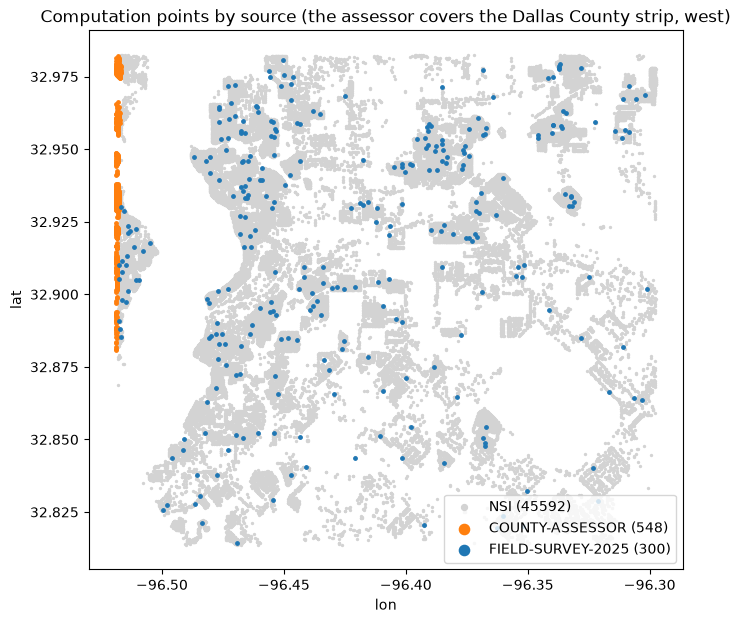

In [19]:
pts = sql(f"SELECT source_ref, x AS lon, y AS lat FROM {BUILDINGS}")
colors = {
    "NSI": "lightgray",
    "COUNTY-ASSESSOR": "tab:orange",
    "FIELD-SURVEY-2025": "tab:blue",
}
fig, ax = plt.subplots(figsize=(8, 7))
for ref, color in colors.items():
    d = pts[pts.source_ref == ref]
    ax.scatter(
        d.lon, d.lat, s=2 if ref == "NSI" else 6, c=color, label=f"{ref} ({len(d)})"
    )
ax.set_aspect(1 / 0.84)  # ~1 / cos(33 deg): equal ground distances
ax.set_title(
    "Computation points by source (the assessor covers the Dallas County strip, west)"
)
ax.set_xlabel("lon")
ax.set_ylabel("lat")
ax.legend(markerscale=3, loc="lower right");

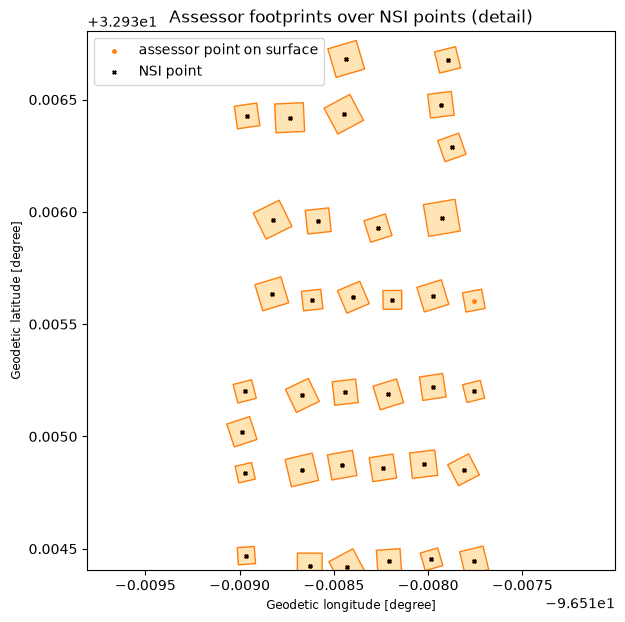

In [20]:
footprints = sql(f"""
SELECT ST_AsText(ST_Transform({sedona_geom_sql("g.geom")}, 'EPSG:3857', 'EPSG:4326')) AS wkt, g.role
FROM {GEOMETRIES} g JOIN {BUILDINGS} b ON g.building_id = b.building_id
WHERE b.source_ref = 'COUNTY-ASSESSOR'
""")
footprints = gpd.GeoDataFrame(
    footprints, geometry=gpd.GeoSeries.from_wkt(footprints.wkt), crs=4326
)
nsi_pts = sql(
    f"SELECT x, y FROM {BUILDINGS} WHERE source_ref = 'NSI' AND cbfips LIKE '48113%'"
)
ax = footprints[footprints.role == "footprint"].plot(
    figsize=(7, 7), facecolor="moccasin", edgecolor="tab:orange"
)
footprints[footprints.role == "point"].plot(
    ax=ax, color="tab:orange", markersize=6, label="assessor point on surface"
)
ax.scatter(nsi_pts.x, nsi_pts.y, s=6, c="black", marker="x", label="NSI point")
# A ~250 m window around the median parcel.
center = footprints[footprints.role == "point"].geometry
cx, cy = center.x.median(), center.y.median()
ax.set_xlim(cx - 0.0014, cx + 0.0014)
ax.set_ylim(cy - 0.0012, cy + 0.0012)
ax.set_title("Assessor footprints over NSI points (detail)")
ax.legend();

**Double counting.** Side-by-side means the same physical structure can
appear once per source. In Dallas County the assessor roll and NSI describe
the same structures, so summing exposure across sources counts them twice.
Choose the sources explicitly for any aggregate (section 7 exports a
source-filtered version). Matching structures across sources (conflation) is
out of scope here.

In [21]:
sql(f"""
SELECT source_ref, COUNT(*) AS n, ROUND(SUM(val_struct) / 1e6, 1) AS val_struct_musd
FROM {BUILDINGS} WHERE cbfips LIKE '48113%' GROUP BY source_ref
UNION ALL
SELECT '(naive sum)', COUNT(*), ROUND(SUM(val_struct) / 1e6, 1)
FROM {BUILDINGS} WHERE cbfips LIKE '48113%'
""")

,source_ref,n,val_struct_musd
0,NSI,546,222.1
1,COUNTY-ASSESSOR,548,222.1
2,(naive sum),1094,444.2


## 5. Scoped reload: assessor release 2

The assessor publishes a new roll with removed parcels, reassessed values and
first-floor elevations, and new parcels. `source_ref` names the dataset lineage,
so the release reuses `COUNTY-ASSESSOR` and the hashed ids stay stable.
Matching parcels compare as unchanged or modified rather than as new. The
`MERGE` deletes only *assessor* buildings that are missing from the release.

In [22]:
%%time
assessor_r2, info = load(
    specs["assessor"],
    syn.assessor.release2,
    "assessor-r2",
    reason="county assessor roll, release 2",
)
pd.Series(info)[
    [
        "version_name",
        "parent_version",
        "source_ref",
        "n_added",
        "n_removed",
        "n_changed",
    ]
]

CPU times: user 492 ms, sys: 365 ms, total: 857 ms
Wall time: 12.5 s


version_name          assessor-r2
parent_version        survey-2025
source_ref        COUNTY-ASSESSOR
n_added                         8
n_removed                      12
n_changed                      25
dtype: object

Every change in the diff from `survey-2025` to `assessor-r2` is an assessor building, and NSI and the survey are untouched:

In [23]:
diff = v.diff_versions(spark, CATALOG, "survey-2025", "assessor-r2")
ids = (
    v.read_version(spark, CATALOG, "survey-2025")
    .select("building_id", "source_ref")
    .unionByName(
        v.read_version(spark, CATALOG, "assessor-r2").select(
            "building_id", "source_ref"
        )
    )
    .distinct()
)
diff.join(ids, "building_id").groupBy("source_ref", "change_kind").count().toPandas()

,source_ref,change_kind,count
0,COUNTY-ASSESSOR,modified,25
1,COUNTY-ASSESSOR,removed,12
2,COUNTY-ASSESSOR,added,8


In [24]:
print(json.dumps(v.diff_summary(diff), indent=2))
pd.concat(
    {
        "survey-2025": per_source(f"{BUILDINGS} VERSION AS OF 'survey-2025'"),
        "assessor-r2": per_source(f"{BUILDINGS} VERSION AS OF 'assessor-r2'"),
    },
    axis=1,
)

{
  "by_kind": {
    "added": 8,
    "removed": 12,
    "modified": 25
  },
  "by_column": {
    "found_ht": 25,
    "val_struct": 25
  }
}


,survey-2025,assessor-r2
source_ref,,
COUNTY-ASSESSOR,548,544
FIELD-SURVEY-2025,300,300
NSI,45592,45592


## 6. A project inventory on a branch

A planned development is assessed on a project branch first: create
`riverbend` from `assessor-r2`, load the project inventory into it, and commit. `main`
does not change until the branch is merged. Nothing changed on `main` in the
meantime, so the merge is a fast-forward.

In [25]:
v.create_branch(spark, CATALOG, "riverbend", "assessor-r2")
riverbend, _ = load(
    specs["riverbend"],
    syn.riverbend,
    "riverbend-plan",
    branch="riverbend",
    editor="planner",
    reason="Riverbend subdivision, preliminary plat",
)
pd.concat(
    {
        "main": per_source(),
        "riverbend": per_source(table_name(CATALOG, "buildings", branch="riverbend")),
    },
    axis=1,
).fillna(0).astype(int)

,main,riverbend
source_ref,,
COUNTY-ASSESSOR,544,544
FIELD-SURVEY-2025,300,300
NSI,45592,45592
PROJECT-RIVERBEND,0,36


In [26]:
merged = v.merge_branch(
    spark,
    CATALOG,
    "riverbend",
    version="riverbend-merged",
    editor="analyst-a",
    reason="approve Riverbend plat",
)
v.drop_branch(spark, CATALOG, "riverbend")
print(merged["mode"], "merge:", merged["n_added"], "buildings added")
registry()

fast-forward merge: 36 buildings added


,version_name,parent_version,merged_version,branch,kind,source_ref,editor,reason,n_buildings,n_added,n_removed,n_changed
0,nsi-sample-v1,—,—,main,release,NSI,analyst-a,Initial load of the NSI sample,45622,45622,0,0
1,nsi-sample-v2,nsi-sample-v1,—,main,release,NSI,analyst-b,"Field survey: FFE corrections, re-geocoded poi...",45597,15,40,150
2,calibration-1,nsi-sample-v2,—,calibration,edit,—,analyst-c,FFE calibration from elevation certificates,45597,0,0,381
3,nsi-sample-v3,nsi-sample-v2,calibration-1,main,merge,—,lead-reviewer,Accept FFE calibration,45597,0,0,381
4,buyout-1,nsi-sample-v3,—,buyout-scenario,edit,—,planner,Acquisition/demolition scenario,45592,0,5,0
5,nsi-sample-v4,nsi-sample-v3,—,main,edit,—,valuation-team,2026 commercial revaluation,45597,0,0,4315
6,nsi-sample-v5,nsi-sample-v4,buyout-1,main,merge,—,lead-reviewer,Adopt buyout scenario,45592,0,5,0
7,review-x-1,nsi-sample-v5,—,review-x,edit,—,reviewer-x,Site visit: raised floor,45592,0,0,1
8,nsi-sample-v6,nsi-sample-v5,—,main,edit,—,valuation-team,Appraisal for one building,45592,0,0,1
9,review-x-2,nsi-sample-v6,—,review-x-rebased,edit,—,reviewer-x,Site visit: raised floor (rebased on v6),45592,0,0,1


## 7. A source-filtered pinned export

`export_version(..., sources=[...])` keeps only the chosen sources. The
`_rqm_version.json` manifest pins the version's snapshots and records the
filter and the row count per source.

In [27]:
out = EXPORTS / "riverbend-merged-nsi-assessor"
manifest = v.export_version(
    spark, CATALOG, "riverbend-merged", out, sources=["NSI", "COUNTY-ASSESSOR"]
)
print(
    json.dumps(
        {
            k: manifest[k]
            for k in ("version", "snapshots", "sources", "rows_by_source", "row_count")
        },
        indent=2,
    )
)
pd.read_parquet(out).groupby("source_ref").size()

{
  "version": "riverbend-merged",
  "snapshots": {
    "buildings": 6754804151051249166,
    "geometries": 4775227324936847527
  },
  "sources": [
    "COUNTY-ASSESSOR",
    "NSI"
  ],
  "rows_by_source": {
    "COUNTY-ASSESSOR": 544,
    "NSI": 45592
  },
  "row_count": 46136
}


source_ref
COUNTY-ASSESSOR      544
NSI                45592
dtype: int64

## 8. Consistency check

`check_consistency` checks the version registry, the tags, and the change log.
At every version it also checks the inventory invariants:
- every `source_ref` is registered in `sources`;
- NSI rows have `building_id = fd_id`;
- every other row's `building_id` is the hash of its `(source_ref, source_record_id)`.

In [28]:
problems = v.check_consistency(spark, CATALOG)
print(problems or "OK: no problems")

OK: no problems


Buildings per source in this notebook's versions, from the NSI base it started on:

In [29]:
v.source_counts(spark, CATALOG).toPandas().pivot(
    index="version_name", columns="source_ref", values="n_buildings"
).fillna(0).astype(int).loc[
    [
        BASE_VERSION,
        "assessor-r1",
        "survey-2025",
        "assessor-r2",
        "riverbend-plan",
        "riverbend-merged",
    ]
]

source_ref,COUNTY-ASSESSOR,FIELD-SURVEY-2025,NSI,PROJECT-RIVERBEND
version_name,,,,
nsi-sample-v7,0,0,45592,0
assessor-r1,548,0,45592,0
survey-2025,548,300,45592,0
assessor-r2,544,300,45592,0
riverbend-plan,544,300,45592,36
riverbend-merged,544,300,45592,36


## 9. Teardown

In [30]:
spark.stop()